In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df = pd.read_excel('/content/student_performance_100.xlsx')

In [ ]:
df

,Student ID,Gender,Ethnicity,Parental Education,Test Preparation,Math Score,Reading Score,Writing Score
0,S001,Male,Group A,Bachelor's Degree,Completed,43,68,68
1,S002,Female,Group E,Associate's Degree,Completed,66,75,54
2,S003,Male,Group E,Some College,Completed,58,59,89
3,S004,Male,Group C,Associate's Degree,NaN,49,52,54
4,S005,Female,Group E,High School,NaN,45,54,35
...,...,...,...,...,...,...,...,...
95,S096,Female,Group D,Associate's Degree,Completed,71,74,60
96,S097,Male,Group C,Associate's Degree,Completed,60,90,58
97,S098,Male,Group A,Associate's Degree,Completed,88,79,58
98,S099,Female,Group C,Bachelor's Degree,Completed,54,73,62


In [ ]:
r,c = df.shape
print(f"Rows:{r} and Columns:{c} in dataset")

Rows:100 and Columns:8 in dataset


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Student ID          100 non-null    object
 1   Gender              100 non-null    object
 2   Ethnicity           100 non-null    object
 3   Parental Education  100 non-null    object
 4   Test Preparation    41 non-null     object
 5   Math Score          100 non-null    int64 
 6   Reading Score       100 non-null    int64 
 7   Writing Score       100 non-null    int64 
dtypes: int64(3), object(5)
memory usage: 6.4+ KB


In [ ]:
df.describe()

,Math Score,Reading Score,Writing Score
count,100.000000,100.000000,100.000000
mean,62.510000,60.490000,60.530000
std,13.600724,12.097662,11.468406
min,34.000000,30.000000,32.000000
25%,52.750000,51.000000,53.000000
50%,63.000000,61.000000,60.500000
75%,72.250000,68.250000,68.000000
max,97.000000,90.000000,89.000000


In [ ]:
df.isnull().sum()

,0
Student ID,0
Gender,0
Ethnicity,0
Parental Education,0
Test Preparation,59
Math Score,0
Reading Score,0
Writing Score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Test Preparation']=df['Test Preparation'].fillna('Not completed')

In [ ]:
df['Test Preparation'].isna().sum()

np.int64(0)

In [ ]:
df['Test Preparation'].value_counts()

,count
Test Preparation,
Not completed,59
Completed,41


In [ ]:
df['Total Score']=df['Math Score'] + df['Reading Score'] + df['Writing Score']
df['Average Score']=df['Total Score']/3

In [ ]:
df['Status'] = np.where((df['Math Score']>=50)&(df['Reading Score']>=50)&(df['Writing Score']>=50),'Pass','Fail')

In [ ]:
df.sample(2)

,Student ID,Gender,Ethnicity,Parental Education,Test Preparation,Math Score,Reading Score,Writing Score,Total Score,Average Score,Status
64,S065,Female,Group E,Associate's Degree,Completed,62,65,71,198,66.0,Pass
47,S048,Female,Group D,High School,Completed,50,65,71,186,62.0,Pass


In [ ]:
df.groupby('Test Preparation')[['Math Score', 'Reading Score', 'Writing Score', 'Average Score']].mean()

,Math Score,Reading Score,Writing Score,Average Score
Test Preparation,,,,
Completed,68.341463,64.609756,66.073171,66.341463
Not completed,58.457627,57.627119,56.677966,57.587571


In [ ]:
# Average score by Gender
print(df.groupby('Gender')[['Math Score', 'Reading Score', 'Writing Score', 'Average Score']].mean())

# Pass rate by Gender
pd.crosstab(df['Gender'], df['Status'], normalize='index') * 100

        Math Score  Reading Score  Writing Score  Average Score
Gender                                                         
Female   63.584906      60.830189      59.377358      61.264151
Male     61.297872      60.106383      61.829787      61.078014


Status,Fail,Pass
Gender,,
Female,32.075472,67.924528
Male,44.680851,55.319149


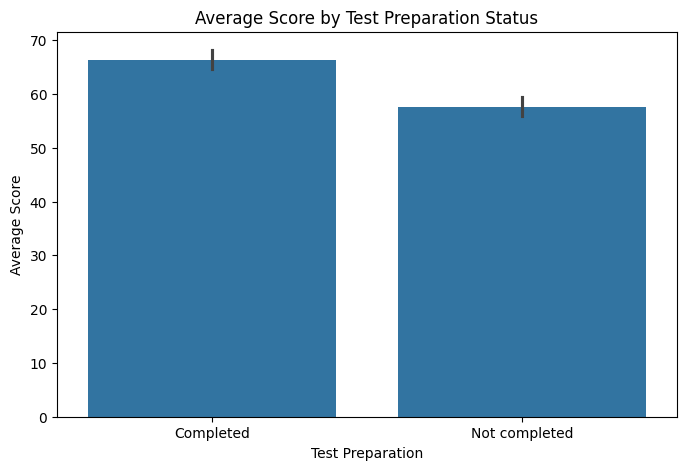

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Test Preparation', y='Average Score', estimator=np.mean)
plt.title('Average Score by Test Preparation Status')
plt.show()

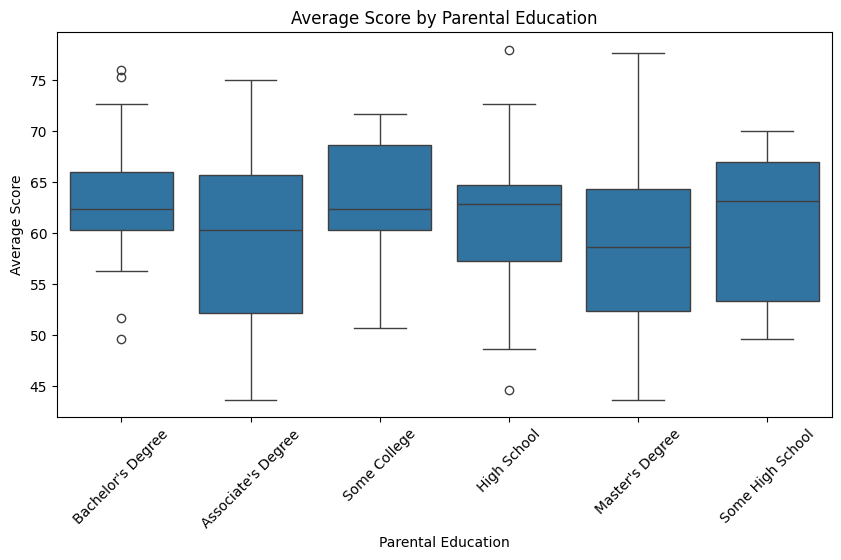

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Parental Education', y='Average Score')
plt.xticks(rotation=45)
plt.title('Average Score by Parental Education')
plt.show()

/tmp/ipykernel_5175/2122881383.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Status', palette='Set2')


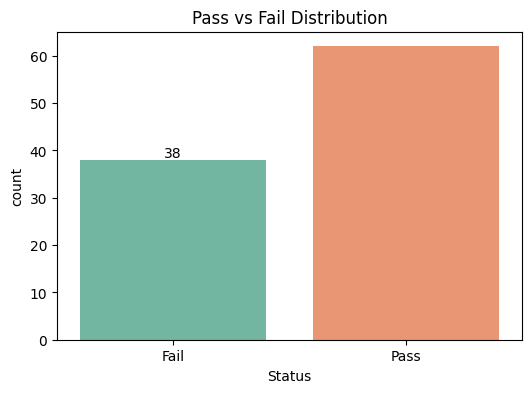

In [ ]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Status', palette='Set2')
ax.bar_label(ax.containers[0])
plt.title('Pass vs Fail Distribution')
plt.show()

In [ ]:
pd.crosstab(df['Test Preparation'], df['Status'], normalize='index') * 100

Status,Fail,Pass
Test Preparation,,
Completed,14.634146,85.365854
Not completed,54.237288,45.762712


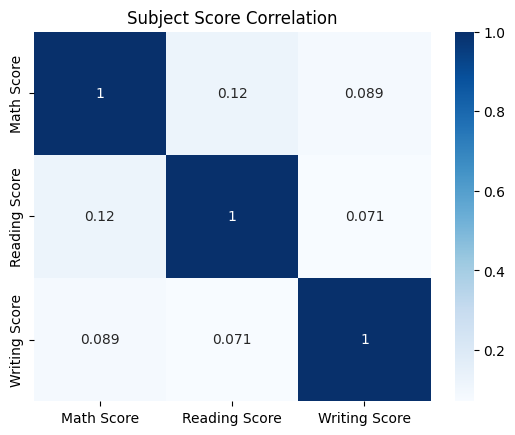

In [ ]:
sns.heatmap(df[['Math Score', 'Reading Score', 'Writing Score']].corr(), annot=True, cmap='Blues')
plt.title('Subject Score Correlation')
plt.show()

## Key Insights & Conclusions

- **Test Preparation Impact:** Completing test preparation is the strongest driver of academic success in this dataset, lifting the pass rate from **45.76%** to **85.37%**.
- **Gender Performance:** While overall average scores between male and female students are nearly identical (~61.1 vs ~61.3), female students achieved a higher overall pass rate (**67.92%** vs **55.32%**) under the $\ge 50$ multi-subject threshold.
- **Subject Correlation:** The three subjects show very weak linear correlation with one another (Math vs Reading: ~0.12, Math vs Writing: ~0.089, Reading vs Writing: ~0.071), indicating individual student strengths vary independently across disciplines.
- **Parental Education:** Students whose parents attained higher education levels (Associate's, Bachelor's, Master's) generally maintained higher median average scores than those with high school backgrounds.

In [ ]:
from google.colab import files

# Save DataFrame to an Excel file
file_name = 'cleaned_student_performance.xlsx'
df.to_excel(file_name, index=False)

# Trigger download to system
files.download(file_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>